# Assessment Cover Page


**Student Full Name**   Vanessa Costa de Brito

**Student Number** 	    2025416

**Module Title**        Machine Learning - FT

**Assessment Title**    CA  1 - Bike-Sharing Usage Patterns and Demand Forecasting

**Lecturer/Supervisor**	Dr. Muhammad Iqbal

**Assessment Due Date**	9th September 2026

**Date of Submission** 	30th October 2026

**Dataset**             day.csv


## Use of AI Tools
**I acknowledge the use of ChatGPT to improve grammar, brainstorming.**


<div style="width: 700px; text-align: justify; text-justify: inter-word;">

<p>This notebook covers data preparation, exploratory analysis, a comparison of two clustering algorithms, and the evaluation of ARIMA and SARIMA forecasts.</p>

</div>

   
## 1. Introduction and Objectives

<div style="width: 700px; text-align: justify; text-justify: inter-word;">
    

### 1.1 - Introduction
<p>Bike-sharing systems are a form of urban transportation. The number of rentals can vary over time, depending on factors such as adverse conditions and the specific day of the week. This project analyzes these patterns using historical data from Capital Bikeshare, provided by the UCI (Fanaee-T, 2013).</p>

### 1.2 - Objectives
<p>The chosen topic allows for the application of machine learning techniques to an everyday scenario, with results that can be interpreted without the need for a complex business context. The objective is to investigate how days can be grouped based on their characteristics and to what extent it is possible to predict the total number of daily rentals.</p>

### 1.3 - The Analytical Questions Are: 

 
* <p>(1) What differences emerge between days, including the impact of adverse conditions?; </p>
  
* <p>(2) Which clustering solution offers the best balance between distinct separation and interpretability? ; and </p> 
    
* <p>(3) How do ARIMA and SARIMA models compare to a simple seasonal forecast? </p>


<p>This study does not aim to establish causality or estimate current demand. Each observation represents a single day, therefore, the clusters reflect profiles of days rather than individual customer profiles. Clustering is an unsupervised learning task.</p>

<p>Time-series forecasting constitutes the second task addressed in this analysis.</p>


</div>

## 02. Data Source and Data Peparation

<div style="width: 700px; text-align: justify; text-justify: inter-word;">


<p>The dataset is available at the following link as mentioned below:</p>

##### <p>https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset</p>
<p>This uses the original daily file provided for the project, without generating any synthetic data. The date serves as a temporal index, <code>instant</code> is simply an identifier, and <code>cnt</code> corresponds to the sum of <code>casual</code> and <code>registred</code> users. Temperature, feels-like temperature, humidity, and wind speed are normalized in the original dataset. </p>
   
<p>Categorical variables encoded as numbers do not automatically represent continuous scales. </p>

</div>

In [1]:
#%pip install --no-cache-dir --force-reinstall --no-deps matplotlib==3.11.2

In [2]:

import warnings
warnings.filterwarnings('ignore') # We can suppress the warnings

In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sklearn, statsmodels

import sys, platform, warnings

from pathlib import Path


from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, mean_absolute_error, mean_squared_error
from sklearn.decomposition import PCA
from scipy.spatial.distance import cdist

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import ConvergenceWarning

In [4]:
random_state=42

plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2})

df = pd.read_csv('day.csv')


display(df.head())

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


## 03. Data Dictionary and Data Quality

<div style="width: 700px; text-align: justify; text-justify: inter-word;">
    
Variable Name |	Role |	Type | Description	Units |	Missing Values
|:---|:---|:---|:---:|:---:|
instant | ID | Integer | record index| no
dteday | Feature | Date | date | no
season | Feature | Categorical | 1:winter, 2:spring, 3:summer, 4:fall | no
yr | Feature | Categorical | year (0:2011, 1:2012) | no
mnth | Feature | Categorical | month (1 to 12) | no
hr | Feature | Categorical | hour (0 to 23) | no
holiday | Feature | Binary | weather day is holiday or not (extracted from http://dchr.dc.gov/page/holiday-schedule) | no
weekday | Feature | Categorical | day of the week | no
workingday | Feature |Binary | if day is neither weekend or holiday is 1, otherwise is 0 | no
weathersit | Feature | Categorical|  - 1: Clear, Few clouds, Partly cloudy, Partly cloudy | no
temp | Feature | Continuous | Normalized temperature in Celsius. The values ​​are derived via (t-t_min)/(t_max-t_min), t_min=-8, t_max=+39 (only in hourly scale) C | no
atemp | Feature | Continuous | Normalized feeling temperature in Celsius. The values ​​are derived via (t-t_min)/(t_max-t_min), t_min=-16, t_max=+50 (only in hourly scale) C | no
hum | Feature | Continuous | Normalized humidity. The values are divided to 100 (max) | no
windspeed | Feature | Continuous | Normalized wind on speed. The values are divided to 67 (max) | no
casual | Other | Integer | count of casual users | no
registered | Other | Integer | count of registered users | no
cnt | Target | Integer | count of total rental bikes including both casual and registered | no







<p>Cleanup is guided by verification, rather than by a need to eliminate records. Days with very low demand may represent actual observations and will be preserved, unless there is evidence of an error.</p>

</div>

In [5]:
# Save a copy of the original data
df_original = df.copy()

#Converting the column to date format
df['dteday'] = pd.to_datetime(df['dteday'], errors='raise')

# Order of dates and indices
df = df.sort_values('dteday').reset_index(drop=True)

# Create the expected calendar
expected = pd.date_range(df['dteday'].min(), df['dteday'].max(), freq='D')


In [6]:
# Check data quality
checks = pd.Series({'lines': len(df),'columns': df.shape[1], 'missing cells': int(df.isna().sum().sum()),
    'duplicate line': int(df.duplicated().sum()), 'duplicate data': int(df['dteday'].duplicated().sum()),
    'missing days calendar': len(expected.difference(df['dteday']) ),'erros casual + registered = cnt': int(
        (df['casual'] + df['registered'] != df['cnt']).sum()),'negative count':
        int((df[['casual', 'registered', 'cnt']] < 0).sum().sum())})

display(checks.to_frame('Result'))
display(df.describe().T)

# Check expected conditions
assert df.isna().sum().sum() == 0
assert not df['dteday'].duplicated().any()
assert len(expected.difference(df['dteday'])) == 0
assert (df['casual'] + df['registered'] == df['cnt']).all()
assert (df[['casual', 'registered', 'cnt']] >= 0).all().all()

# Check the normalized variables
for col in ['temp', 'atemp', 'hum', 'windspeed']:
    assert df[col].between(0, 1).all(), f'Check Interval of {col}'

# Remove the identifier from the prepared base
clean = df.drop(columns='instant').copy()

# Confirm the minimum number of columns required in CA1
assert clean.shape[1] >= 7

print(f'Data Preparation: {clean.shape[0]} Days and '
    f'{clean.shape[1]} colunms. No lines were removed.')

,Result
lines,731
columns,16
missing cells,0
duplicate line,0
duplicate data,0
missing days calendar,0
erros casual + registered = cnt,0
negative count,0


,count,mean,min,25%,50%,75%,max,std
instant,731.0,366.0,1.0,183.5,366.0,548.5,731.0,211.165812
dteday,731,2012-01-01 00:00:00,2011-01-01 00:00:00,2011-07-02 12:00:00,2012-01-01 00:00:00,2012-07-01 12:00:00,2012-12-31 00:00:00,NaN
season,731.0,2.49658,1.0,2.0,3.0,3.0,4.0,1.110807
yr,731.0,0.500684,0.0,0.0,1.0,1.0,1.0,0.500342
mnth,731.0,6.519836,1.0,4.0,7.0,10.0,12.0,3.451913
holiday,731.0,0.028728,0.0,0.0,0.0,0.0,1.0,0.167155
weekday,731.0,2.997264,0.0,1.0,3.0,5.0,6.0,2.004787
workingday,731.0,0.683995,0.0,0.0,1.0,1.0,1.0,0.465233
weathersit,731.0,1.395349,1.0,1.0,1.0,2.0,3.0,0.544894
temp,731.0,0.495385,0.05913,0.337083,0.498333,0.655417,0.861667,0.183051


Data Preparation: 731 Days and 15 colunms. No lines were removed.


<div style="width: 700px; text-align: justify; text-justify: inter-word;">

<p>Final Test – November and December 2012</p>
<p>Initial Training – January 2011 to August 2012</p>
<p>Validation – September and October 2012</p>
<p>The exploration that guides the forecast uses only the development period, up to October 2012.</p>
<p>The clustering describes the 731 days retrospectively and is not used as an input for the temporal model.</p>

</div>


In [7]:
series = clean.set_index('dteday')['cnt'].asfreq('D').astype(float)
train = series.loc[:'2012-08-31']
valid = series.loc['2012-09-01':'2012-10-31']
dev = series.loc[:'2012-10-31']
test = series.loc['2012-11-01':]
eda = clean[clean.dteday <= '2012-10-31'].copy()
display(pd.DataFrame([{'Set': name, 'Inicial': s.index.min(), 'Final': s.index.max(), 'Days': len(s)}
                      for name,s in [('Train',train),('Valid',valid),('Test',test)]]))
assert train.index.max() < valid.index.min() and valid.index.max() < test.index.min()

,Set,Inicial,Final,Days
0,Train,2011-01-01,2012-08-31,609
1,Valid,2012-09-01,2012-10-31,61
2,Test,2012-11-01,2012-12-31,61


## 04.Exploratory Analysis

<div style="width: 700px; text-align: justify; text-justify: inter-word;">


<p>In this stage, explore the data from January 2011 to October 2012 to identify patterns, while keeping November and December separate for the final testing of the forecasting models.</p>

</div>

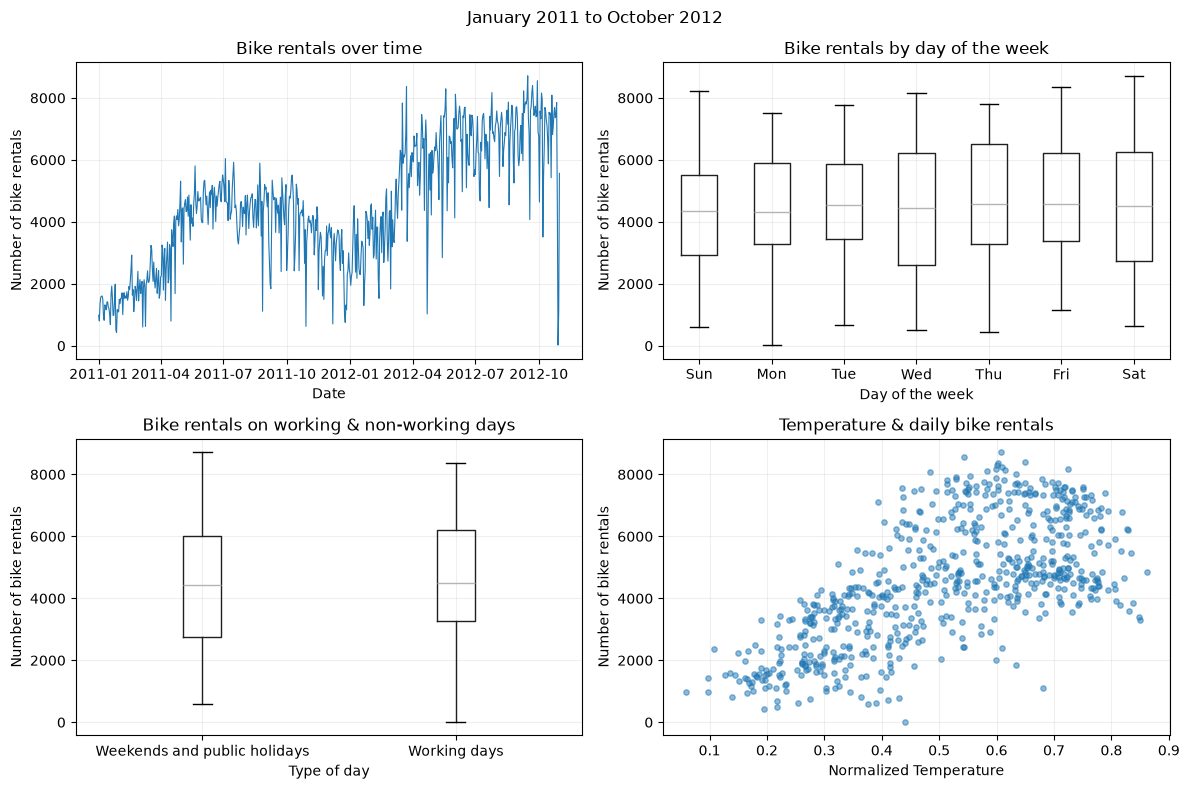

,count,mean,median
weathersit,,,
1,429,4871.3,4780.0
2,221,4023.0,3974.0
3,20,1871.4,1829.5


,count,mean
yr,,
0,365,3405.8
1,305,5813.8


Correlation Temperature & Feels Like: 0.991


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0,0].plot(dev.index, dev.values, linewidth=.8)
axes[0,0].set(title='Bike rentals over time', xlabel='Date', ylabel='Number of bike rentals')
eda.boxplot(column='cnt', by='weekday', ax=axes[0,1])

axes[0,1].set(title='Bike rentals by day of the week', xlabel='Day of the week', ylabel='Number of bike rentals')
axes[0, 1].set_xticklabels(['Sun', 'Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat'])
eda.boxplot(column='cnt', by='workingday', ax=axes[1,0])

axes[1,0].set(title='Bike rentals on working & non-working days', xlabel='Type of day', ylabel='Number of bike rentals')
axes[1, 0].set_xticklabels(['Weekends and public holidays', 'Working days'])

axes[1,1].scatter(eda.temp, eda.cnt, alpha=.5, s=15)
axes[1,1].set(title='Temperature & daily bike rentals', xlabel='Normalized Temperature', ylabel='Number of bike rentals')

fig.suptitle('January 2011 to October 2012'); fig.tight_layout(); plt.show()

display(eda.groupby('weathersit').cnt.agg(['count','mean','median']).round(1))
display(eda.groupby('yr').cnt.agg(['count','mean']).round(1))

print('Correlation Temperature & Feels Like:', round(eda.temp.corr(eda.atemp),3))

### 04.1 - Analysis Results

<div style="width: 700px; text-align: justify; text-justify: inter-word;">
    
<p>The charts allow for the comparison of distribution and dispersion, rather than looking solely at averages. When comparing across years, it should be noted that the development dataset covers only a portion of 2012. The association between temperature and demand does not imply causality and may also reflect the time of year. "Feels-like" temperature (apparent temperature) will be excluded from the clustering process to avoid redundant information already captured by the actual temperature. Rare weather conditions and holidays warrant caution, as they are represented by fewer observations.</p>

<p>In the development dataset, values ​​tend to rise throughout part of 2011, decline during the colder period, and increase again in 2012. There are isolated drops that merit further investigation. Boxplots for weekdays versus non-weekdays show significant overlap; this distinction alone does not clearly differentiate demand levels. The temperature chart reveals a positive association for much of the range, though with notable dispersion and a potential shift in behavior at higher temperatures.</p>

</div>

<div style="width: 700px; text-align: justify; text-justify: inter-word;">
    
<p>Seven original variables were selected: <code>temp</code>, <code>hum</code>, <code>windspeed</code>, <code>weathersit</code>,<code>workingday</code>, <code>holiday</code>, and <code>mnth</code>. The month is represented using sine and cosine transformations to ensure that December and January are positioned close to each other. Continuous variables and cyclic coordinates are standardized; weather conditions are one-hot encoded; and binary indicators are kept as 0 or 1. This combination defines a distance metric for exploration, though the weighting of these variables remains a limitation.</p>

<p>The variables <code>cnt</code>, <code>casual</code>, and <code>registered</code> are excluded: the clusters are constructed based on context, with demand examined subsequently. We compare K-Means with Ward’s hierarchical clustering, generating between two and six clusters using the same matrix. K-Means is sensitive to initialization and tends to favor compact clusters. Ward’s method produces a hierarchical structure of merges, also promoting compactness (scikit-learn developers, s.d.).</p>

</div>

,algorithm,k,silhouette,davies_bouldin,smallest_cluster_size
0,KMeans,2,0.2600,1.5536,353
1,KMeans,3,0.2390,1.5211,207
2,KMeans,4,0.2277,1.3923,134
3,KMeans,5,0.2159,1.4094,112
4,KMeans,6,0.2207,1.4239,89
5,Ward,2,0.1900,1.9877,338
6,Ward,3,0.1953,1.6442,138
7,Ward,4,0.1876,1.5300,138
8,Ward,5,0.1747,1.6235,93
9,Ward,6,0.1661,1.5882,49


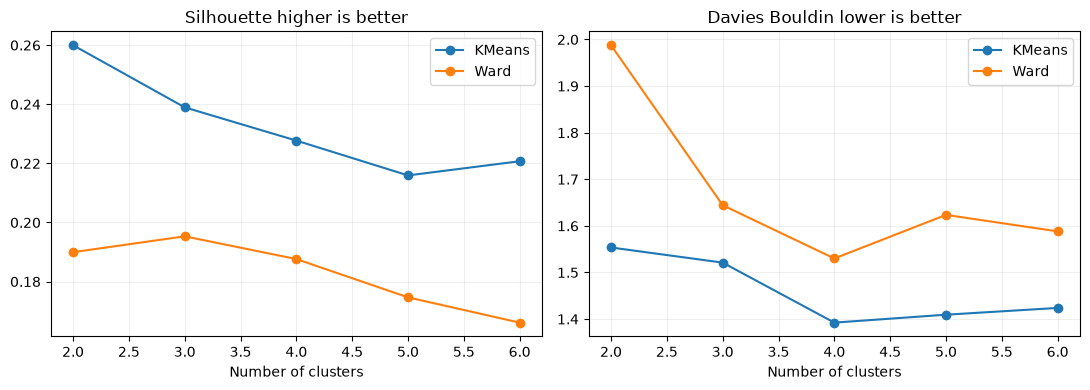

In [9]:
features = ['temp','hum','windspeed','weathersit','workingday','holiday','mnth']
context = clean[features].copy()
context['month_sin'] = np.sin(2*np.pi*context.mnth/12)
context['month_cos'] = np.cos(2*np.pi*context.mnth/12)
num = ['temp','hum','windspeed','month_sin','month_cos']
prep = ColumnTransformer([('numeric', StandardScaler(), num), ('weather', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['weathersit']),
    ('binary', 'passthrough', ['workingday','holiday'])])
X = prep.fit_transform(context)
records, labels_by_model = [], {}
for method in ['KMeans','Ward']:
    for k in range(2,7):
        model = KMeans(n_clusters=k, n_init=20, random_state=42) if method=='KMeans' else AgglomerativeClustering(n_clusters=k, linkage='ward')
        labels = model.fit_predict(X)
        labels_by_model[(method,k)] = labels
        records.append({'algorithm': method, 'k': k,
                        'silhouette': silhouette_score(X, labels),
                        'davies_bouldin': davies_bouldin_score(X, labels),
                        'smallest_cluster_size': int(np.bincount(labels).min())})
cluster_scores = pd.DataFrame(records)
display(cluster_scores.round(4))
fig, axes = plt.subplots(1,2,figsize=(11,4))
for name,g in cluster_scores.groupby('algorithm'):
    axes[0].plot(g.k,g.silhouette,marker='o',label=name)
    axes[1].plot(g.k,g.davies_bouldin,marker='o',label=name)
axes[0].set(title='Silhouette higher is better',xlabel='Number of clusters')
axes[1].set(title='Davies Bouldin lower is better',xlabel='Number of clusters')
for ax in axes: ax.legend()
    
plt.tight_layout(); plt.show()

### Evaluation and Selection Rule

<div style="width: 700px; text-align: justify; text-justify: inter-word;">
    
<p>The silhouette score compares the average distance within a cluster to the distance to the nearest neighboring cluster; it ranges from −1 to 1, with higher values indicating better separation. The Davies–Bouldin index summarizes the similarity between each cluster and its most similar counterpart, accounting for both dispersion and the distance between centroids; lower values ​​are preferable. There is no universal threshold that elevates a specific clustering result to an absolute truth about the data.</p>

<p>As a reproducible rule, I select the configuration with the highest silhouette score, using the Davies–Bouldin index as a tie-breaker. This rule does not replace the need for interpretation: I examine cluster sizes, profiles, and the stability of the K-Means algorithm across different initializations. Note that a PCA visualization is merely a projection, whereas the metrics are calculated based on the full dataset matrix.</p>

</div>

,dias,procura_media,temperatura,umidade,vento,proporcao_dias_uteis,proporcao_feriados
cluster,,,,,,,
0,378,3460.217,0.346,0.604,0.208,0.664,0.034
1,353,5622.428,0.655,0.653,0.171,0.705,0.023


weathersit,1,2,3
cluster,,,
0,0.601,0.362,0.037
1,0.669,0.312,0.020


,0,1
0,0.00,2.52
1,2.52,0.00


Distâncias euclidianas entre os centroides no espaço transformado, não em unidades originais.
Estabilidade KMeans ARI em três sementes: [0.995 0.995 1.   ]


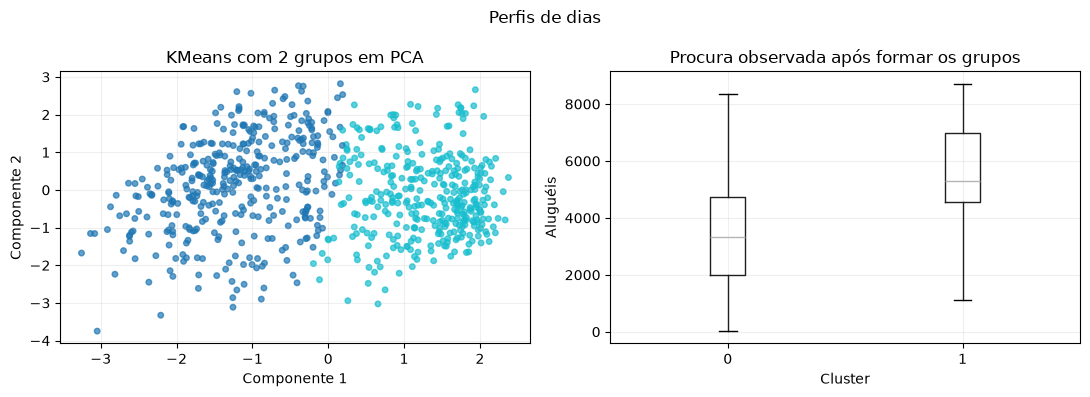

Result: KMeans, k=2, Silhouette: 0.260, Davies–Bouldin: 1.554


In [10]:
chosen = cluster_scores.sort_values(['silhouette','davies_bouldin'], ascending=[False,True]).iloc[0]
method, k = chosen.algorithm, int(chosen.k)
labels = labels_by_model[(method,k)]
profile = clean.assign(cluster=labels)
summary = profile.groupby('cluster').agg(dias=('cnt','size'), procura_media=('cnt','mean'),
    temperatura=('temp','mean'), umidade=('hum','mean'), vento=('windspeed','mean'),
    proporcao_dias_uteis=('workingday','mean'), proporcao_feriados=('holiday','mean'))
display(summary.round(3))
display(pd.crosstab(profile.cluster, profile.weathersit, normalize='index').round(3))
centers = np.vstack([X[labels==i].mean(axis=0) for i in range(k)])
display(pd.DataFrame(cdist(centers,centers), index=range(k),columns=range(k)).round(2))
print('Distâncias euclidianas entre os centroides no espaço transformado, não em unidades originais.')
best_km = int(cluster_scores.query("algorithm == 'KMeans'").sort_values('silhouette',ascending=False).iloc[0].k)
base_labels = labels_by_model[('KMeans', best_km)]
stability = [adjusted_rand_score(base_labels,KMeans(n_clusters=best_km,n_init=20,random_state=s).fit_predict(X)) for s in [1,7,21]]
print('Estabilidade KMeans ARI em três sementes:', np.round(stability,3))
coords = PCA(n_components=2).fit_transform(X)
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(coords[:,0],coords[:,1],c=labels,cmap='tab10',s=16,alpha=.7)
axes[0].set(title=f'{method} com {k} grupos em PCA',xlabel='Componente 1',ylabel='Componente 2')
profile.boxplot(column='cnt',by='cluster',ax=axes[1])
axes[1].set(title='Procura observada após formar os grupos',xlabel='Cluster',ylabel='Aluguéis')
fig.suptitle('Perfis de dias'); fig.tight_layout(); plt.show()
print(
    f'Result: {method}, k={k}, '
    f'Silhouette: {chosen.silhouette:.3f}, '
    f'Davies–Bouldin: {chosen.davies_bouldin:.3f}'
)

<div style="width: 700px; text-align: justify; text-justify: inter-word;">

<p>Resultado: a regra selecionou <strong>Kmeans</strong>, <strong>k=2</strong>, com silhouette <strong>0.260</strong> e Davies–Bouldin <strong>1.554</strong>. Os rótulos são identificadores sem ordem. As diferenças de procura descrevem os grupos, mas não provam causalidade.</p>


</div>


### Discussion of Clustering Comparison

<div style="width: 700px; text-align: justify; text-justify: inter-word;">

<p>K-Means with two clusters yields a silhouette score of approximately 0.260, which is higher than that of the other alternatives evaluated. However, the lowest Davies–Bouldin index is observed with K-Means using four clusters. The metrics do not yield the same ranking; the preference for two clusters aligns with the stated selection criterion and provides a simpler description.</p> 

<p>The relatively low silhouette score and the overlap observed in the PCA projection indicate limited separation. Consequently, the clusters should be interpreted as an exploratory synthesis of contexts, rather than as evidence for the existence of two natural categories of days.

<p>In the configurations tested, the Ward method produces a lower silhouette score than K-Means. While this justifies the preference for K-Means within this specific transformation and range of cluster counts, it does not imply that the algorithm is superior in all cases.</p>


</div>

## 06. Temporal Exploration and Parameter Selection

<div style="width: 700px; text-align: justify; text-justify: inter-word;">


<p>STL decomposition with a period of seven explores a weekly pattern in the data. The visual presence of a trend or seasonality does not guarantee predictive capability. The residuals from the decomposition may highlight unusual days, but identifying a specific cause requires consulting external sources.</p>

<p>In ARIMA, <code>p</code> represents the autoregressive order, <code>d</code> the degree of differencing, and <code>q</code> the moving average order. In SARIMA, <code>P</code>,<code>D</code>, and <code>Q</code> represent seasonal terms, with a period of <code>s=7</code> in this investigation. ACF, PACF, and ADF plots guide a targeted search, while temporal validation is used to select among the candidate models. Two years of data are insufficient to reliably assess complex annual seasonality (statsmodels developers, s.d.).</p>


</div>

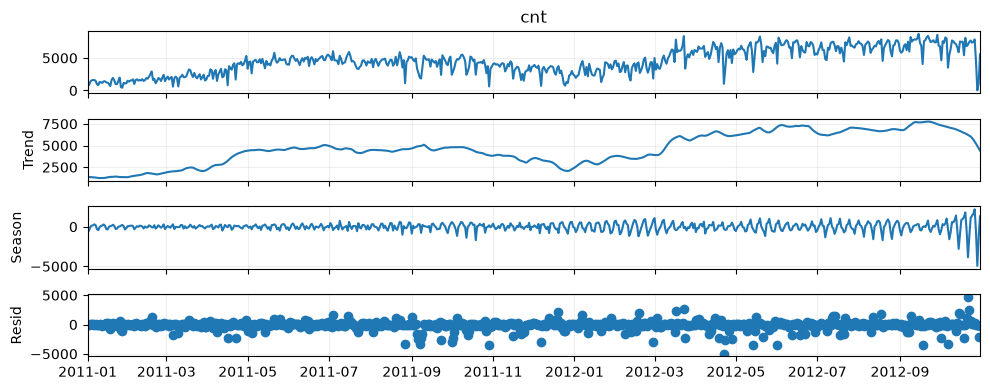

,Absolute STL Residual
dteday,
2012-04-22,4952.374244
2012-10-22,4691.202941
2012-09-18,3568.187834
2012-05-14,3539.108461
2012-06-01,3469.284977


,serie,ADF statistic,p-value,Lags used
0,Original training Series,-1.2921,0.6328,13
1,First-differenced training series,-10.9383,0.0000,12


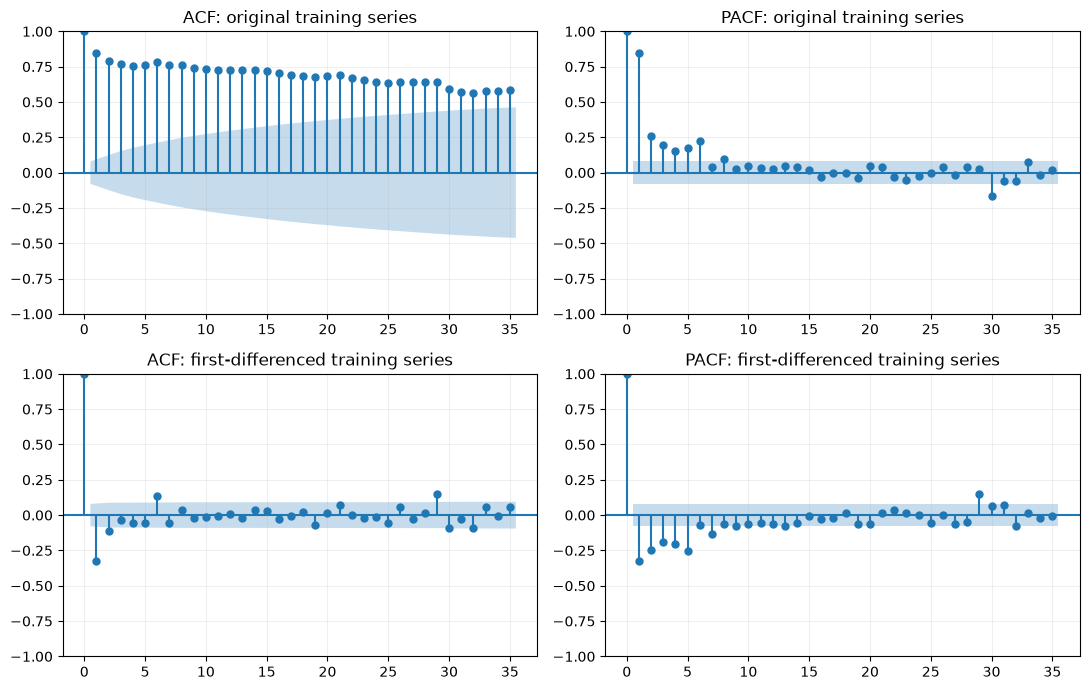

In [11]:
stl = STL(dev, period=7, robust=True).fit()
stl.plot(); plt.tight_layout(); plt.show()
display(stl.resid.abs().nlargest(5).to_frame('Absolute STL Residual'))
adf_rows=[]
for name,s in [('Original training Series',train),('First-differenced training series',train.diff().dropna())]:
    r=adfuller(s,autolag='AIC')
    adf_rows.append({'serie':name,'ADF statistic':r[0], 'p-value':r[1],'Lags used':r[2]})
display(pd.DataFrame(adf_rows).round(4))
fig,axes=plt.subplots(2,2,figsize=(11,7))
plot_acf(train,lags=35,ax=axes[0,0]); plot_pacf(train,lags=35,method='ywm',ax=axes[0,1])
plot_acf(train.diff().dropna(),lags=35,ax=axes[1,0]); plot_pacf(train.diff().dropna(),lags=35,method='ywm',ax=axes[1,1])
axes[0,0].set_title('ACF: original training series'); axes[0,1].set_title('PACF: original training series')
axes[1,0].set_title('ACF: first-differenced training series'); axes[1,1].set_title('PACF: first-differenced training series')
plt.tight_layout(); plt.show()

### Interpretation of Plots and Stationarity Tests

<div style="width: 700px; text-align: justify; text-justify: inter-word;">

<p>In the training set, the Augmented Dickey-Fuller (ADF) test in levels yields a p-value of approximately 0.633; therefore, the null hypothesis of a unit root cannot be rejected. After the first difference, the p-value is less than 0.001. The Autocorrelation Function (ACF) in levels decays slowly, while the first-differenced series shows a stronger negative correlation at the first lag. These findings suggest comparing models d=0 and d=1 and incorporating low-order Moving Average (MA) terms, rather than selecting a model based solely on visual inspection of the plots. Seasonal differencing D=1 is also evaluated among the SARIMA candidates; the final model selection is determined through validation.</p>

<p>The STL decomposition reveals a time-varying trend, a weekly component with fluctuating amplitude, and residuals characterized by sharp drops. Notably, April 22 and October 22, 2012, appear among the dates with the largest absolute residuals. These serve as exploratory indicators of unusual days; however, I do not attribute specific causes to them in the absence of external evidence. Furthermore, the weekly decomposition does not explicitly account for an annual cycle and should not be interpreted as definitive proof that seasonality is exclusively weekly.</p>

### Forecasting and Benchmark Protocol

<div style="width: 700px; text-align: justify; text-justify: inter-word;">


<p>Forecasts are evaluated for a <strong>one-day-ahead horizon with daily updates</strong>. Once a one-day forecast is made, the corresponding observed value becomes available for forecasting the next day; model parameters remain fixed throughout each window. The benchmark forecast uses the observed value from seven days prior, operating under the exact same information availability constraints.</p>

<p>The search process outlined below compares low-order models—both with and without differencing and seasonal components. Configurations that fail or do not converge are recorded and excluded from the selection. The validation MAE (Mean Absolute Error) serves as the primary criterion, while the AIC (Akaike Information Criterion) is provided as supplementary information. This search is limited in scope and does not aim to identify a global optimum.</p>

</div>

In [16]:
def fit_model(y, order, seasonal):
    trend = 'c' if order[1] == 0 and seasonal[1] == 0 else 'n'
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        result = SARIMAX(y,order=order,seasonal_order=seasonal,trend=trend,
                         enforce_stationarity=True,enforce_invertibility=True).fit(disp=False,maxiter=150)
    converged = bool(result.mle_retvals.get('converged',True))
    return result, converged, len(caught)

def rolling_one_step(fitted, observed):
    values,lower,upper=[],[],[]
    current=fitted
    for date,value in observed.items():
        f=current.get_forecast(steps=1)
        ci=np.asarray(f.conf_int(alpha=.05))[0]
        values.append(float(np.asarray(f.predicted_mean)[0]))
        lower.append(float(ci[0])); upper.append(float(ci[1]))
        current=current.append(pd.Series([value],index=pd.DatetimeIndex([date],freq='D'),name=observed.name),refit=False)
    return pd.DataFrame({'forecast':values,'lower':lower,'upper':upper},index=observed.index)

orders=[(1,0,0),(2,0,0),(1,0,1),(1,1,0),(0,1,1),(1,1,1)]
seasonals=[(0,0,0,0),(1,0,0,7),(0,1,1,7)]
search=[]
for order in orders:
    for seasonal in seasonals:
        family='ARIMA' if seasonal==(0,0,0,0) else 'SARIMA'
        try:
            fit,converged,nwarn=fit_model(train,order,seasonal)
            if not converged:
                search.append(dict(family=family,order=order,seasonal=seasonal,status='did not converge', warn=nwarn))
                continue
            pred=rolling_one_step(fit,valid)['forecast']
            search.append(dict(family=family,order=order,seasonal=seasonal,status='ok',warn=nwarn,
                MAE=mean_absolute_error(valid,pred),RMSE=np.sqrt(mean_squared_error(valid,pred)),AIC=fit.aic))
        except Exception as exc:
            search.append(dict(family=family,order=order,seasonal=seasonal,status=str(exc)[:120]))
search_table=pd.DataFrame(search)
display(search_table.sort_values('MAE').round(2))
baseline_valid=series.shift(7).loc[valid.index]
print('MAE validation:',round(mean_absolute_error(valid,baseline_valid),2))
eligible=search_table[search_table.status=='ok'].copy()
assert set(eligible['family'])=={'ARIMA','SARIMA'}, 'Check model configurations and convergence.'
best_by_family=eligible.sort_values('MAE').groupby('family',sort=False).head(1)
winner=eligible.sort_values('MAE').iloc[0]
print(
    f"Model selected before evaluating the test set: "
    f"{winner['family']} {winner.order} × {winner.seasonal}. "
    f"Validation MAE: {winner.MAE:.2f}"
)

,family,order,seasonal,status,warn,MAE,RMSE,AIC
2,SARIMA,"(1, 0, 0)","(0, 1, 1, 7)",ok,0.0,881.47,1341.75,9930.08
17,SARIMA,"(1, 1, 1)","(0, 1, 1, 7)",ok,0.0,890.25,1407.62,9836.15
5,SARIMA,"(2, 0, 0)","(0, 1, 1, 7)",ok,0.0,891.09,1351.85,9921.83
15,ARIMA,"(1, 1, 1)","(0, 0, 0, 0)",ok,0.0,928.33,1416.72,9927.71
16,SARIMA,"(1, 1, 1)","(1, 0, 0, 7)",ok,0.0,930.44,1417.99,9929.65
14,SARIMA,"(0, 1, 1)","(0, 1, 1, 7)",ok,0.0,938.86,1504.48,9870.84
8,SARIMA,"(1, 0, 1)","(0, 1, 1, 7)",ok,0.0,940.91,1502.38,9884.40
12,ARIMA,"(0, 1, 1)","(0, 0, 0, 0)",ok,0.0,993.14,1524.39,9962.68
13,SARIMA,"(0, 1, 1)","(1, 0, 0, 7)",ok,0.0,996.37,1525.18,9967.45
6,ARIMA,"(1, 0, 1)","(0, 0, 0, 0)",ok,0.0,1000.80,1518.21,9984.34


MAE validation: 1164.34
Model selected before evaluating the test set: SARIMA (1, 0, 0) × (0, 1, 1, 7). Validation MAE: 881.47


<div style="width: 700px; text-align: justify; text-justify: inter-word;">

<p> Model chosen before starting the test: <strong>SARIMA (1, 0, 0) × (0, 1, 1, 7)</strong> , Validation MAE   <strong>881.47</strong>.</p>

</div>

## 07. Final Testing


<div style="width: 700px; text-align: justify; text-justify: inter-word;">


<p>The best candidate from each family—identified throughout the development process—is re-evaluated during the final testing period. The model that performed best during validation remains the chosen one, even if the ranking shifts during this final test. MAE represents the mean absolute error in rental prices, while RMSE assigns greater weight to larger errors. Predictions were neither rounded nor truncated prior to evaluation.</p>
    
<p>The 95% intervals express uncertainty based on the model's underlying assumptions; their observed coverage is calculated below.</p>

</div>

,modelo,MAE,RMSE,coverage_95,negative_forecasts
model,,,,,
NaN,Weekly,1486.705,1968.910,NaN,NaN
SARIMA,NaN,943.631,1263.771,0.836,0.0
ARIMA,NaN,769.490,1078.832,0.852,0.0


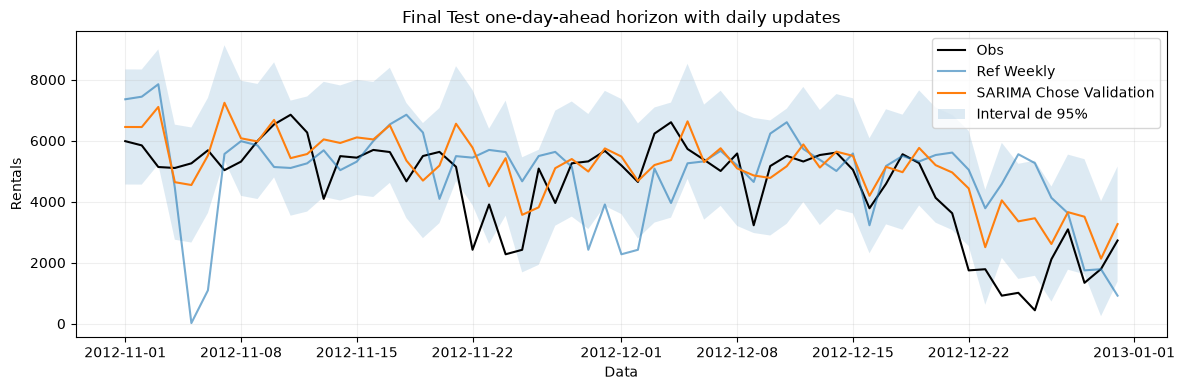

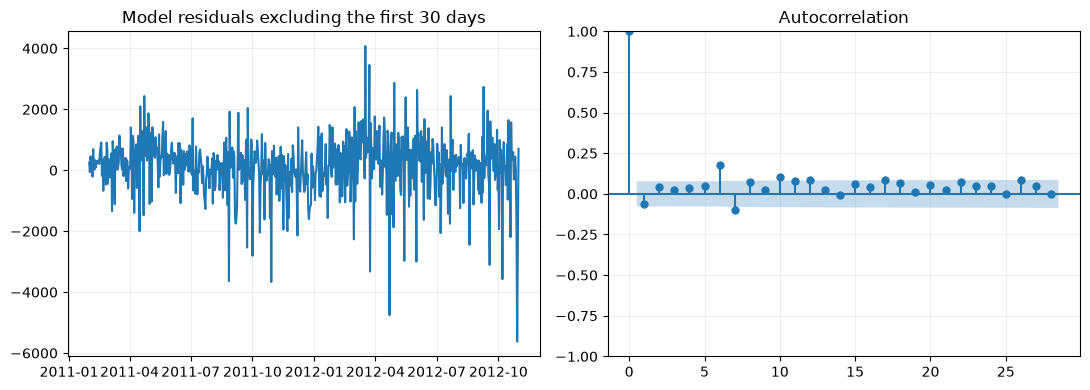

,lb_stat,lb_pvalue
7,32.229692,0.000037
14,52.167028,0.000003
21,66.072190,0.000001


Ljung-Box: a small p-value suggests residual autocorrelation. This is an exploratory result without adjustment for the model's degrees of freedom.


,observ,forecast,absolute_error
dteday,,,
2012-11-22,2425.0,5774.8,3349.8
2012-11-24,2277.0,5427.4,3150.4
2012-12-24,920.0,4045.1,3125.1
2012-12-26,441.0,3458.4,3017.4
2012-12-22,1749.0,4435.3,2686.3


In [18]:
test_rows=[]; forecasts={}; fitted_models={}
base=series.shift(7).loc[test.index]
test_rows.append({'modelo':'Weekly','MAE':mean_absolute_error(test,base),'RMSE':np.sqrt(mean_squared_error(test,base))})
for _,row in best_by_family.iterrows():
    fit,conv,nwarn=fit_model(dev,row.order,row.seasonal)
    assert conv, f"did not converge: {row['family']}"
    pred=rolling_one_step(fit,test)
    name=row['family']; forecasts[name]=pred; fitted_models[name]=fit
    test_rows.append({'model':name,'MAE':mean_absolute_error(test,pred['forecast']),
        'RMSE':np.sqrt(mean_squared_error(test,pred['forecast'])),
        'coverage_95':((test>=pred.lower)&(test<=pred.upper)).mean(),
        'negative_forecasts':int((pred['forecast']<0).sum())})
results=pd.DataFrame(test_rows).set_index('model')
display(results.round(3))
selected=winner['family']; forecast=forecasts[selected]
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(test.index,test,label='Obs',color='black')
ax.plot(test.index,base,label='Ref Weekly',alpha=.6)
ax.plot(test.index,forecast['forecast'],label=f'{selected} Chose Validation')
ax.fill_between(test.index,forecast.lower,forecast.upper,alpha=.15,label='Interval de 95%')
ax.set(title='Final Test one-day-ahead horizon with daily updates',ylabel='Rentals',xlabel='Data')
ax.legend(); plt.tight_layout(); plt.show()
selected_fit=fitted_models[selected]
residuals=pd.Series(np.asarray(selected_fit.resid),index=dev.index).iloc[30:]
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(residuals.index,residuals); axes[0].set_title('Model residuals excluding the first 30 days')
plot_acf(residuals,lags=28,ax=axes[1]); plt.tight_layout(); plt.show()
display(acorr_ljungbox(residuals,lags=[7,14,21],return_df=True))
print("Ljung-Box: a small p-value suggests residual autocorrelation. This is an exploratory result without adjustment for the model's degrees of freedom.")
errors=(test-forecast['forecast']).abs().sort_values(ascending=False)
display(pd.DataFrame({'observ':test,'forecast':forecast['forecast'],'absolute_error':errors}).loc[errors.head(5).index].round(1))

## 08. Analysis of the Conclusion

<div style="width: 700px; text-align: justify; text-justify: inter-word;">
    
<p>The results below are calculated based on the outputs, avoiding the premature inclusion of metrics or conclusions. While clustering can support the description of usage contexts, it does not demonstrate that the chosen variables cause the demand.</p>

<p>The temporal model must be interpreted within the context of the evaluated horizon: forecasting for a single day with daily updates is different from forecasting for a two-month period without any new observations.</p>


</div>

### 08.1 Summary of Observed Results


<div style="width: 700px; text-align: justify; text-justify: inter-word;">
    
<p>The analysis utilized 731 days and retained 15 columns after removing the identifier. The data checks did not necessitate the removal of any rows.</p>

<p>For clustering, the K-Means algorithm with 2 clusters was selected. The silhouette score was 0.260, and the Davies–Bouldin index was 1.554. These metrics evaluate the structure within the transformed space and should be interpreted in conjunction with the cluster profiles.</p>
</p>
<p>Cluster 0 comprised 378 days, with an average demand of 3,460 rentals, a mean normalized temperature of 0.346, and 66.4% of days falling on weekdays.</p>

<p>Cluster 1 comprised 353 days, with an average demand of 5,622 rentals, a mean normalized temperature of 0.655, and 70.5% of days falling on weekdays.</p>

<p>For forecasting, the SARIMA model was selected based on the validation process. In the testing phase, it yielded an MAE of 943.6 rentals and an RMSE of 1,263.8. The MAE was 36.5% lower than that of the weekly baseline (1,486.7).</p>

<p>Ultimately, the choice of model should take into account error metrics, simplicity, and diagnostic results. If the baseline model yields a lower error, there is no evidence in this test to recommend the more complex model as a superior alternative.</p>

</div>

### 08.2 Forecasting and Diagnostics

<div style="width: 700px; text-align: justify; text-justify: inter-word;">
    
<p>During validation, the SARIMA (1,0,0) × (0,1,1,7) model yielded the lowest MAE among the models that converged—approximately 881.47 rentals. One configuration resulted in a numerical error; it was recorded in the table but excluded from the selection process. The absence of standard differencing (d=0) in the winning model does not imply that the original series is stationary, as the model incorporates seasonal differencing (D=1).</p>

<p>In the final test, the selected SARIMA model produced an MAE of 943.63 and an RMSE of 1263.77. The best-performing ARIMA model from the validation phase, (1,1,1), achieved an MAE of 769.49 and an RMSE of 1078.83 in this test. The weekly baseline model yielded an MAE of 1486.70 and an RMSE of 1968.91. Thus, the SARIMA model reduced the MAE by approximately 36.5% compared to the baseline, while the ARIMA model performed even better during this final period. I have retained the SARIMA model based on the validation results, noting that the shift in performance ranking—where the ARIMA model outperformed the SARIMA—highlights that model performance is period-dependent; however, I have not altered the original selection based on these test results.</p>

<p>The nominal 95% prediction intervals covered approximately 83.6% of the observations for the SARIMA model and 85.2% for the ARIMA model. This coverage, which falls below the nominal level, suggests that uncertainty was underestimated in this test. Consequently, relying solely on these predicted bounds for resource planning should be done with caution. Furthermore, the magnitude of the largest errors and the presence of autocorrelation in the residuals should be considered alongside the average error metrics. The one-day-ahead evaluation relies on actual observed values following each forecast; therefore, the model’s performance may not be as robust over longer horizons without periodic updates.</p>

Referência

<p>IQBAL, M. (2026a) Introduction to Machine Learning (ML). Lecture notes. Dublin: CCT College Dublin.</p>

<p>IQBAL, M. (2026b) Lecture 2: Introduction to Clustering (ML). Lecture notes. Dublin: CCT College Dublin.</p>

https://ipython.readthedocs.io/en/stable/api/generated/IPython.display.html (Accessed:26th October).